# 第4回　浅いニューラルネットワークと分類問題

「学習済みの特徴の上に，線形分類器を1つ載せる」ことを NumPy で確かめる．

| 節 | テーマ |
|---|---|
| §1 | ロジスティック回帰の数値例 |
| §2 | 決定境界を描く |
| §3 | ロジスティック回帰を学習する |
| §4 | ソフトマックス分類器 |
| §5 | 線形プローブ：表現の良さを測る |
| §6 | 少量データでの適応方式の選択 |
| §7 | （任意）PyTorch での凍結 |

用語：**バックボーン**＝特徴を計算する部分（入力 → 特徴 $\boldsymbol{z}$）．**ヘッド**＝特徴からクラスを決める最後の層．
**凍結**＝パラメータを更新しないこと．特徴 $\boldsymbol{z}$ は「表現」とも呼ぶ（同じ意味）．

```{admonition} この章の使い方
:class: tip
ページ右上のロケットのボタンから Colab で開くか，[環境構築](setup.md) に従って手元で実行する．セルは **上から順に** 実行する．
**やってみよう** は `# TODO` の行を書き換えて再実行する（先に結果を予想してから）．「補助コード」と書いたセルは本題ではない補助の実装で，中身は読まなくてよい（折りたたんである）．
詳しくは [ノートブックの使い方](usage.md)．
```

In [1]:
import os
os.environ.setdefault('OMP_NUM_THREADS', '1')        # 小さな行列の計算では並列化が逆に遅くなるので 1 コアで計算する
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')   # （numpy を読み込む前に設定する必要がある）
os.environ.setdefault('MKL_NUM_THREADS', '1')
import numpy as np
import matplotlib.pyplot as plt
try:
    import matplotlib_fontja                       # 図の日本語フォント（pip install matplotlib-fontja）
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "matplotlib-fontja"], check=False)
    import matplotlib_fontja
np.set_printoptions(precision=3, suppress=True)
rng = np.random.default_rng(0)

def sigmoid(u):
    return 1.0 / (1.0 + np.exp(-u))

def softmax_rows(U):
    U = U - U.max(axis=1, keepdims=True)
    E = np.exp(U)
    return E / E.sum(axis=1, keepdims=True)

## §1 ロジスティック回帰の数値例

$$p(y=1\mid \boldsymbol{z}) = \sigma(\boldsymbol{w}^\top\boldsymbol{z}+b)$$

講義の例：$\boldsymbol{w}=(1,1)^\top$，$b=-2$．つまりスコアは $u=z_1+z_2-2$．

In [2]:
w = np.array([1.0, 1.0])
b = -2.0
for z in ([0.0, 0.0], [2.0, 2.0], [1.0, 1.0]):
    u = w @ np.array(z) + b
    print(f"z={z}: スコア u={u:+.1f}, クラス1の確率 p={sigmoid(u):.2f}")
# (0,0) → 0.12，(2,2) → 0.88，(1,1) は境界上で 0.50

z=[0.0, 0.0]: スコア u=-2.0, クラス1の確率 p=0.12
z=[2.0, 2.0]: スコア u=+2.0, クラス1の確率 p=0.88
z=[1.0, 1.0]: スコア u=+0.0, クラス1の確率 p=0.50


**やってみよう 1-1**　$\boldsymbol{z}=(1, 1.5)$ のクラス1の確率はいくらか．先に $u$ を暗算してから実行する．

In [3]:
z = np.array([1.0, 1.5])     # TODO: 別の点でも試す
print("u =", w @ z + b, " p =", sigmoid(w @ z + b))   # u = 0.5 → p ≈ 0.62

u = 0.5  p = 0.6224593312018546


## §2 決定境界を描く

決定境界は $\boldsymbol{w}^\top\boldsymbol{z}+b=0$（確率がちょうど 0.5 になる点の集まり）．2次元なら直線になる．
$\boldsymbol{w}$ は境界に垂直で，確率が増える向きを指す．

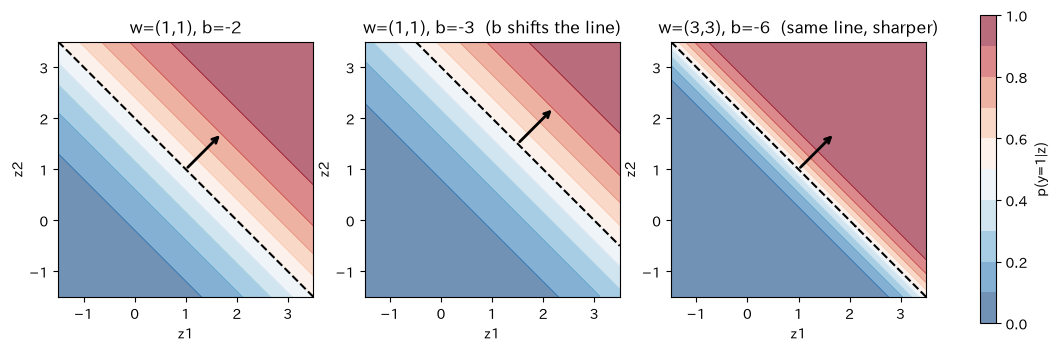

In [4]:
# 補助コード：決定境界を描く関数（中身は読まなくてよい）．
#   色＝クラス1の確率（赤いほど 1 に近い），破線＝確率 0.5 の境界，矢印＝w の向き
def plot_boundary(w, b, ax, title=''):
    g1, g2 = np.meshgrid(np.linspace(-1.5, 3.5, 200), np.linspace(-1.5, 3.5, 200))
    Pgrid = sigmoid(w[0] * g1 + w[1] * g2 + b)
    cs = ax.contourf(g1, g2, Pgrid, levels=np.linspace(0, 1, 11), cmap='RdBu_r', alpha=0.6)
    ax.contour(g1, g2, Pgrid, levels=[0.5], colors='k', linestyles='--')
    # 境界上の点から w の向きに矢印
    p0 = -b * w / (w @ w)                      # 原点から境界に下ろした垂線の足（矢印の根元にするだけ）
    ax.annotate('', xy=p0 + w / np.linalg.norm(w), xytext=p0, arrowprops=dict(arrowstyle='->', lw=2))
    ax.set_aspect('equal'); ax.set_xlabel('z1'); ax.set_ylabel('z2'); ax.set_title(title)
    return cs

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
plot_boundary(np.array([1.0, 1.0]), -2.0, ax[0], 'w=(1,1), b=-2')
plot_boundary(np.array([1.0, 1.0]), -3.0, ax[1], 'w=(1,1), b=-3  (b shifts the line)')
cs = plot_boundary(np.array([3.0, 3.0]), -6.0, ax[2], 'w=(3,3), b=-6  (same line, sharper)')
fig.colorbar(cs, ax=ax, label='p(y=1|z)'); plt.show()

**読み取り**　$b$ を変えると境界が平行移動する．$\boldsymbol{w}$ と $b$ を同じ倍率で大きくすると境界の位置は同じまま，確率の変化が急になる（自信が強くなる）．

**やってみよう 2-1**　境界を縦線 $z_1=1$ にするには $\boldsymbol{w}$ と $b$ をどう決めるか．

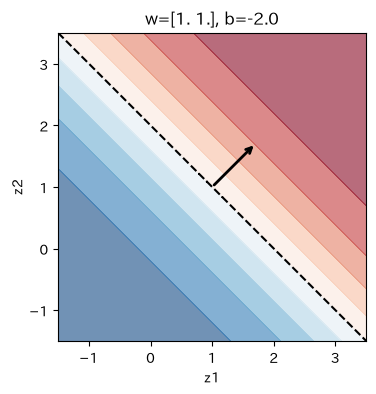

In [5]:
w_try = np.array([1.0, 1.0])     # TODO: 境界が縦線 z1 = 1 になるように書き換える
b_try = -2.0                     # TODO
fig, ax = plt.subplots(figsize=(4.5, 4))
plot_boundary(w_try, b_try, ax, f'w={w_try}, b={b_try}')
plt.show()

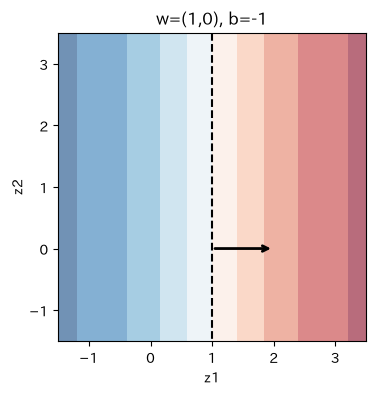

In [6]:
# 解答：z2 の重みを 0 にすると，スコアは z1 だけで決まる．u = z1 − 1 なので w = (1, 0)，b = −1．
fig, ax = plt.subplots(figsize=(4.5, 4))
plot_boundary(np.array([1.0, 0.0]), -1.0, ax, 'w=(1,0), b=-1')
plt.show()

## §3 ロジスティック回帰を学習する

二値交差エントロピーの勾配は「（予測確率 − 正解）× 入力特徴」（第2回，第3回 と同じ形）．

$$\frac{\partial L}{\partial \boldsymbol{w}} = \frac{1}{N}\sum_n (p_n-y_n)\,\boldsymbol{z}_n,\qquad \frac{\partial L}{\partial b} = \frac{1}{N}\sum_n (p_n-y_n)$$

$n$ はデータの番号（全部で $N$ 件）．
**L2 正則化**（引数 `l2`）：重みが大きくなりすぎないよう，損失に $\frac{\lambda}{2}\|\boldsymbol{w}\|^2$ を足すこと．勾配には $\lambda\boldsymbol{w}$ が加わる．

データ：傷のない画像の特徴が $(0,0)$ 付近，傷のある画像の特徴が $(2,2)$ 付近に分布しているとする．

学習した w = [2.966 2.894], b = -5.73, 正解率 = 0.945
境界：2.97 z1 + 2.89 z2 + (-5.73) = 0  →  z1 + z2 ≈ 1.96


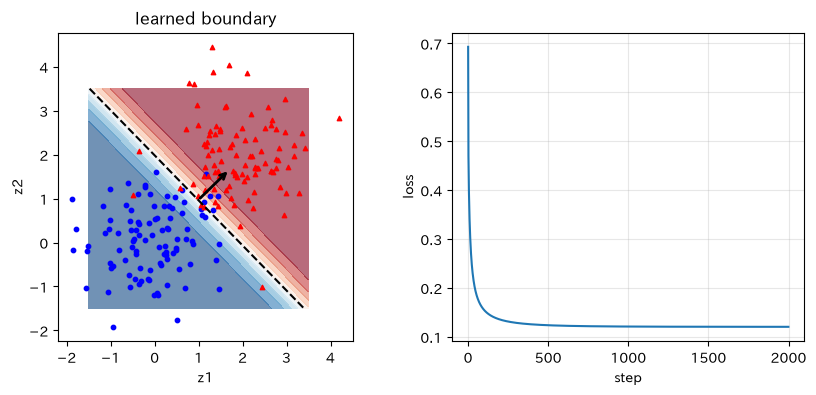

In [7]:
def make_blobs(n, std, seed=0):
    r = np.random.default_rng(seed)
    Z = np.concatenate([r.normal([0, 0], std, size=(n, 2)), r.normal([2, 2], std, size=(n, 2))])
    y = np.concatenate([np.zeros(n), np.ones(n)])
    return Z, y

def train_logreg(Z, y, lr=0.5, steps=2000, l2=0.0):
    w = np.zeros(Z.shape[1]); b = 0.0
    hist = []
    for t in range(steps):
        p = sigmoid(Z @ w + b)
        # Z.T @ (p − y) は Σ_n (p_n − y_n) z_n をまとめて計算したもの（Z は 1 行が 1 件のデータ）
        gw = Z.T @ (p - y) / len(y) + l2 * w      # （予測 − 正解）× 特徴 （＋ L2 正則化）
        gb = np.mean(p - y)
        w -= lr * gw; b -= lr * gb
        loss = -np.mean(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12))
        hist.append((loss, np.linalg.norm(w)))
    return w, b, np.array(hist)

Z, y = make_blobs(100, std=0.8)
w_hat, b_hat, hist = train_logreg(Z, y)
acc = np.mean((sigmoid(Z @ w_hat + b_hat) > 0.5) == (y == 1))
print(f"学習した w = {w_hat}, b = {b_hat:.2f}, 正解率 = {acc:.3f}")
print(f"境界：{w_hat[0]:.2f} z1 + {w_hat[1]:.2f} z2 + ({b_hat:.2f}) = 0  →  z1 + z2 ≈ {-b_hat / w_hat.mean():.2f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
plot_boundary(w_hat, b_hat, ax[0], 'learned boundary')
ax[0].scatter(Z[y == 0, 0], Z[y == 0, 1], s=10, c='b'); ax[0].scatter(Z[y == 1, 0], Z[y == 1, 1], s=10, c='r', marker='^')
ax[1].plot(hist[:, 0]); ax[1].set_xlabel('step'); ax[1].set_ylabel('loss'); ax[1].grid(alpha=0.3)
plt.show()

**やってみよう 3-1**　2 クラスが**完全に分離**できるデータ（`std=0.2`）で学習を長く続けると，$\|\boldsymbol{w}\|$ はどうなるか．
L2 正則化（`l2=0.01`）を入れるとどう変わるか．
**先に予想を書く**：正則化なしの $\|\boldsymbol{w}\|$ は（増え続ける／ある値で止まる）．

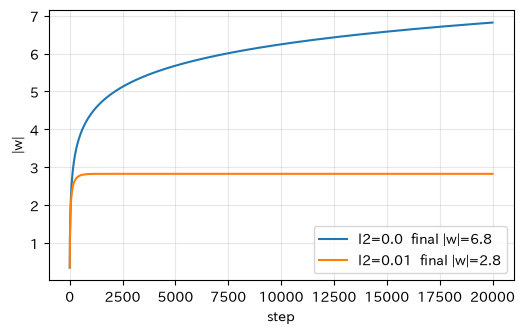

In [8]:
Zs, ys = make_blobs(100, std=0.2)
plt.figure(figsize=(6, 3.5))
for l2 in (0.0, 0.01):                      # TODO: 値を変える
    _, _, h = train_logreg(Zs, ys, steps=20000, l2=l2)
    plt.plot(h[:, 1], label=f'l2={l2}  final |w|={h[-1, 1]:.1f}')
plt.xlabel('step'); plt.ylabel('|w|'); plt.legend(); plt.grid(alpha=0.3); plt.show()
# 解答：正則化なしでは |w| が増え続ける（確率を 0/1 に近づけるほど損失が下がるので終わりがない）．
#       L2 正則化を入れると有限の値で止まる．

## §4 ソフトマックス分類器

$K$ クラスでは，クラスごとに重みベクトルを持つ：$W\in\mathbb{R}^{K\times d}$，$\boldsymbol{b}\in\mathbb{R}^K$．パラメータ数は $dK+K$．
勾配は同じ形：$(P-Y)^\top Z/N$．

W の形 = (3, 2)  パラメータ数 = d*K + K = 9
正解率 = 0.9833333333333333


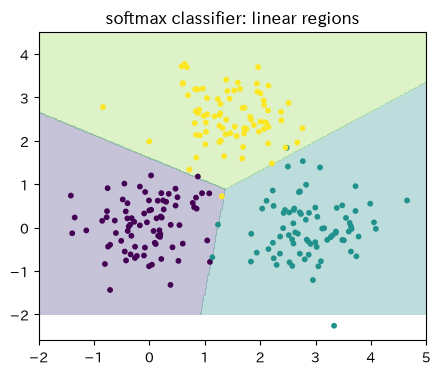

In [9]:
def train_softmax(Z, y, K, lr=0.5, steps=2000, l2=0.0, seed=0):
    N, d = Z.shape
    W = np.zeros((K, d)); b = np.zeros(K)
    Y = np.eye(K)[y]                           # ラベル 2 → (0,0,1) のような 1-hot に変換
    for t in range(steps):
        P = softmax_rows(Z @ W.T + b)
        W -= lr * ((P - Y).T @ Z / N + l2 * W)     # (P − Y).T @ Z は，各データの (p − y) z^T の和（K×d の表）
        b -= lr * (P - Y).mean(axis=0)
    return W, b

def predict(W, b, Z):
    return (Z @ W.T + b).argmax(axis=1)

# 3 クラスのデータ
centers = np.array([[0, 0], [3, 0], [1.5, 2.5]])
Z3 = np.concatenate([rng.normal(c, 0.6, size=(80, 2)) for c in centers])
y3 = np.repeat(np.arange(3), 80)
W3, b3 = train_softmax(Z3, y3, K=3)
print("W の形 =", W3.shape, " パラメータ数 = d*K + K =", W3.size + b3.size)
print("正解率 =", np.mean(predict(W3, b3, Z3) == y3))

g1, g2 = np.meshgrid(np.linspace(-2, 5, 300), np.linspace(-2, 4.5, 300))
R = predict(W3, b3, np.stack([g1.ravel(), g2.ravel()], 1)).reshape(g1.shape)
plt.figure(figsize=(5, 4)); plt.contourf(g1, g2, R, levels=[-0.5, 0.5, 1.5, 2.5], alpha=0.3, cmap='viridis')
plt.scatter(Z3[:, 0], Z3[:, 1], c=y3, s=10, cmap='viridis'); plt.title('softmax classifier: linear regions'); plt.show()

**やってみよう 4-1**　特徴 768 次元，10 クラスの線形ヘッドのパラメータ数はいくつか．バックボーン（ViT-B/16 で約 8,600 万個）の何 % か．

In [10]:
d, K = 768, 10
n_head = d * K + K
print(n_head, f"個．バックボーンの {100 * n_head / 86e6:.4f} %")   # 7,690 個，約 0.009 %

7690 個．バックボーンの 0.0089 %


## §5 線形プローブ：表現の良さを測る

本物の事前学習済みモデルの代わりに，小さな MLP を **別のタスクで事前学習** してバックボーンにする．

- 入力：2次元の点 $\boldsymbol{x}$（半径 3 の円の中に一様）
- **事前学習タスク**（ラベルが豊富，2,000 件）：原点からの距離で 4 つの輪に分類する
- **下流タスク**（ラベルが少ない，20 件）：「内側（距離 < 2）か外側か」の 2 値分類．事前学習の輪の境目（0.75, 1.5, 2.25）とは違う場所で切る
- バックボーンは 2 → 32 → 8 の MLP．最後の 8 次元が特徴 $\boldsymbol{z}$

どちらのタスクも「原点からの距離」が分かれば解ける．事前学習でバックボーンが距離を表す特徴を作るので，下流タスクでも再利用できるはず，という設定である．

線形プローブの手順：① バックボーンを凍結して特徴を計算 → ② 特徴の上で線形分類器だけを学習 → ③ テスト精度を報告．
これを 3 種類の特徴で比べる：(a) 入力そのまま，(b) ランダム初期値のままのバックボーン，(c) 事前学習したバックボーン．

注意：簡単のため検証データは使わず，学習率は固定し，テストデータの正解率（＝講義の「精度」）で比べる．本来は講義のとおり，設定は検証データで選ぶ．

In [11]:
# ---- 補助コード：小さな MLP（隠れ層 tanh，出力ソフトマックス）．中身は第3回の逆伝播そのもので，読まなくてよい．
#      見るのは train の中の `if l == last or train_backbone:` の 1 行だけ．
#      train_backbone=False のとき，最後の層（ヘッド）以外は更新されない ＝ バックボーンの凍結．
#      tanh は第2回の活性化関数の一つ（出力が −1〜1）．微分は 1 − tanh²．
def init_mlp(sizes, seed=0):
    r = np.random.default_rng(seed)
    return [dict(W=r.normal(size=(sizes[l], sizes[l - 1])) / np.sqrt(sizes[l - 1]), b=np.zeros(sizes[l]))
            for l in range(1, len(sizes))]

def copy_params(params):
    return [dict(W=p['W'].copy(), b=p['b'].copy()) for p in params]

def features(params, X):
    # バックボーン＝最後の層（ヘッド）を除いた部分．その出力が特徴 z．
    Z = X
    for layer in params[:-1]:
        Z = np.tanh(Z @ layer['W'].T + layer['b'])
    return Z

def logits(params, X):
    return features(params, X) @ params[-1]['W'].T + params[-1]['b']

def accuracy(params, X, y):
    return float(np.mean(logits(params, X).argmax(1) == y))

def train(params, X, y, steps=800, lr=0.5, train_backbone=True):
    # train_backbone=False なら，ヘッド（最後の層）だけを更新する ＝ バックボーンを凍結
    params = copy_params(params)
    N = len(y); K = params[-1]['W'].shape[0]; Y = np.eye(K)[y]
    last = len(params) - 1
    for t in range(steps):
        acts = [X]
        for layer in params[:-1]:
            acts.append(np.tanh(acts[-1] @ layer['W'].T + layer['b']))
        D = (softmax_rows(acts[-1] @ params[-1]['W'].T + params[-1]['b']) - Y) / N     # D ＝ 誤差信号 δ（出力層は p − y）
        for l in range(last, -1, -1):
            gW = D.T @ acts[l]; gb = D.sum(axis=0)
            D_next = (D @ params[l]['W']) * (1 - acts[l] ** 2) if l > 0 else None   # δ の再帰（1 − a² は tanh の微分）
            if l == last or train_backbone:        # ← 凍結のとき，ヘッド（l == last）だけを更新する
                params[l]['W'] -= lr * gW; params[l]['b'] -= lr * gb
            D = D_next
    return params

def new_head(backbone_params, K, seed=0):
    # バックボーンはそのまま，ヘッドだけ新しい（K クラス用の）線形層に付け替える
    params = copy_params(backbone_params)
    d = params[-1]['W'].shape[1]
    params[-1] = dict(W=np.zeros((K, d)), b=np.zeros(K))
    return params

# ---- データ
def sample_disc(n, seed):
    r = np.random.default_rng(seed)
    rad = 3.0 * np.sqrt(r.uniform(size=n)); th = r.uniform(0, 2 * np.pi, n)
    return np.stack([rad * np.cos(th), rad * np.sin(th)], axis=1)

def label_rings(X):          # 事前学習タスク：4 つの輪（距離 0〜0.75 → 0，〜1.5 → 1，〜2.25 → 2，それ以上 → 3）
    return np.minimum((np.linalg.norm(X, axis=1) / 0.75).astype(int), 3)

def label_inner(X):          # 下流タスク（近いドメイン）：内側か外側か
    return (np.linalg.norm(X, axis=1) < 2.0).astype(int)

X_pre = sample_disc(2000, seed=1); y_pre = label_rings(X_pre)
X_test = sample_disc(2000, seed=2)

# ---- 事前学習（ラベルが豊富なタスクで，バックボーンごと学習）
pretrained = train(init_mlp([2, 32, 8, 4], seed=0), X_pre, y_pre, steps=3000, lr=0.5)
print("事前学習タスクの正解率 =", accuracy(pretrained, X_test, label_rings(X_test)))

事前学習タスクの正解率 = 0.9555


(a) raw input x             : 線形プローブのテスト正解率 = 0.503
(b) random backbone         : 線形プローブのテスト正解率 = 0.490


(c) pretrained backbone     : 線形プローブのテスト正解率 = 0.966


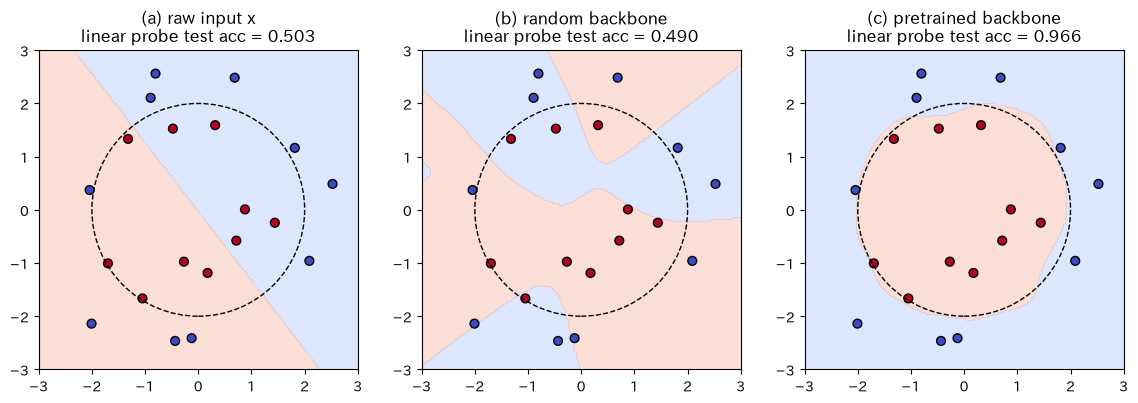

In [12]:
# ---- 下流タスク：ラベルは 20 件だけ
X_small = sample_disc(20, seed=3); y_small = label_inner(X_small)
y_test = label_inner(X_test)

random_backbone = init_mlp([2, 32, 8, 4], seed=5)          # 学習していないバックボーン

# (a) は層が [2, 2] ＝ 隠れ層なし ＝ 入力 x に直接，線形分類器を載せたもの
probes = {
    '(a) raw input x':            train(init_mlp([2, 2], seed=0), X_small, y_small, train_backbone=False),
    '(b) random backbone':        train(new_head(random_backbone, 2), X_small, y_small, train_backbone=False),
    '(c) pretrained backbone':    train(new_head(pretrained, 2), X_small, y_small, train_backbone=False),
}
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
g1, g2 = np.meshgrid(np.linspace(-3, 3, 200), np.linspace(-3, 3, 200))
G = np.stack([g1.ravel(), g2.ravel()], 1)
for a, (name, pr) in zip(ax, probes.items()):
    acc = accuracy(pr, X_test, y_test)
    a.contourf(g1, g2, logits(pr, G).argmax(1).reshape(g1.shape), levels=[-0.5, 0.5, 1.5], alpha=0.3, cmap='coolwarm')
    a.scatter(X_small[:, 0], X_small[:, 1], c=y_small, cmap='coolwarm', edgecolors='k', s=40)
    a.add_patch(plt.Circle((0, 0), 2.0, fill=False, ls='--'))
    a.set_aspect('equal'); a.set_title(f"{name}\nlinear probe test acc = {acc:.3f}")
    print(f"{name:28s}: 線形プローブのテスト正解率 = {acc:.3f}")
plt.show()

**図の見方**　背景色＝分類器の予測，点＝ラベル付きの 20 件，破線の円＝正解の境界．

**読み取り**　3 つとも学習したのは**線形分類器だけ**で，ラベルも同じ 20 件．違うのは特徴だけ．
(a) 入力空間では直線でしか切れないので，正解率は，でたらめに答えた場合（0.5）と変わらない．(b) 学習していないバックボーンの特徴も役に立たない．
(c) 事前学習した特徴の上では，同じ線形分類器が，入力空間で見ると円形の境界を作る（破線の円が正解の境界）．
線形プローブの精度の差 ＝ 表現の質の差，と読める．

**やってみよう 5-1**　ラベル数を 20 → 5 や 200 に変えると (a)(b)(c) の差はどうなるか．
**やってみよう 5-2**　学習するパラメータの数を数える．(c) で学習したのはヘッドの何個か．バックボーンは何個か．

In [13]:
n_head = probes['(c) pretrained backbone'][-1]['W'].size + probes['(c) pretrained backbone'][-1]['b'].size
n_backbone = sum(p['W'].size + p['b'].size for p in pretrained[:-1])
print(f"ヘッド {n_head} 個（学習），バックボーン {n_backbone} 個（凍結）")

# 少量データでは「どの点が選ばれたか」で結果が大きく変わるので，選び方を 5 通り変えて平均する
for n in (5, 20, 200):                           # TODO: 値を変える
    accs = []
    for trial in range(5):
        Xs = sample_disc(n, seed=1000 * trial + n); ys = label_inner(Xs)
        if len(np.unique(ys)) < 2:
            continue                             # 片方のクラスしか含まれない選び方は除く
        accs.append([accuracy(train(p0, Xs, ys, train_backbone=False), X_test, y_test)
                     for p0 in (init_mlp([2, 2], seed=0), new_head(random_backbone, 2), new_head(pretrained, 2))])
    a = np.mean(accs, axis=0)
    print(f"n={n:4d}: raw {a[0]:.3f} / random {a[1]:.3f} / pretrained {a[2]:.3f}（{len(accs)} 通りの平均）")

ヘッド 18 個（学習），バックボーン 360 個（凍結）


n=   5: raw 0.524 / random 0.527 / pretrained 0.886（5 通りの平均）


n=  20: raw 0.531 / random 0.518 / pretrained 0.955（5 通りの平均）


n= 200: raw 0.527 / random 0.519 / pretrained 0.980（5 通りの平均）


## §6 少量データでの適応方式の選択

3 つの方式を，ラベル数 $n$ を変えて比べる．

| 方式 | 初期値 | 学習する部分 |
|---|---|---|
| 線形プローブ | 事前学習済み | ヘッドのみ |
| フル Fine-tuning | 事前学習済み | 全部（小さめの学習率） |
| ゼロから学習 | ランダム | 全部 |

下流タスクは 2 種類：**近いドメイン**（内側か外側か．事前学習と同じく距離で決まる）と，
**遠いドメイン**（$x_1 x_2 > 0$ か．角度で決まり，距離は無関係）．

- この演習では入力の分布はどれも同じで，「ラベルの決め方が事前学習と似ているか（近い）違うか（遠い）」でドメイン差の代わりとする．
-講義の段階のうち，両端（線形プローブとフル Fine-tuning）だけを比べる．「ゼロから学習」は，事前学習を使わない場合の比較対象．
- 下のセルは実行に 1 分ほどかかる（PC によっては 2 分）．読むのはグラフ：横軸＝ラベル数 $n$（対数），縦軸＝テスト正解率．

near domain: inner vs outer    linear probe     : n=10:0.85  n=30:0.96  n=100:0.98  n=1000:0.98
near domain: inner vs outer    full fine-tuning : n=10:0.85  n=30:0.92  n=100:0.96  n=1000:0.99
near domain: inner vs outer    from scratch     : n=10:0.60  n=30:0.77  n=100:0.95  n=1000:0.97


far domain: x1*x2 > 0          linear probe     : n=10:0.62  n=30:0.73  n=100:0.76  n=1000:0.78
far domain: x1*x2 > 0          full fine-tuning : n=10:0.66  n=30:0.80  n=100:0.92  n=1000:0.97
far domain: x1*x2 > 0          from scratch     : n=10:0.64  n=30:0.90  n=100:0.95  n=1000:0.99


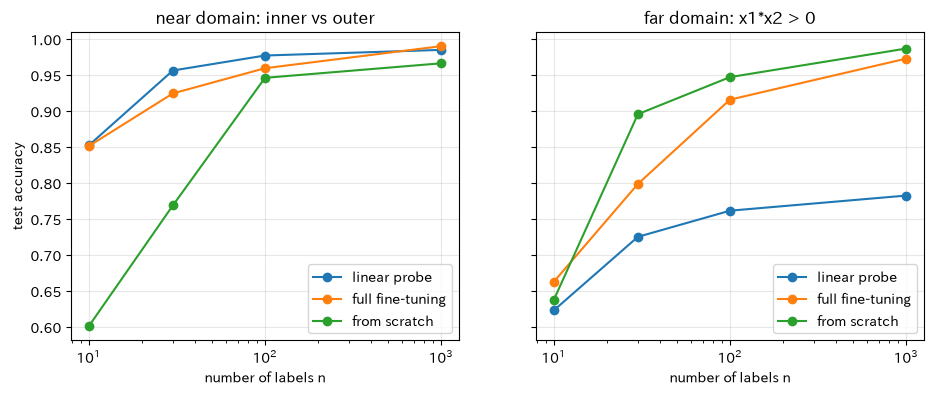

In [14]:
def label_quadrant(X):        # 下流タスク（遠いドメイン）：第1・第3象限か
    return (X[:, 0] * X[:, 1] > 0).astype(int)

# 補助コード：ラベル数 n を変えて 3 方式を学習し，テスト正解率を 3 回平均する（中身は読まなくてよい）
def compare(label_fn, ns=(10, 30, 100, 1000), n_seeds=3):
    res = {'linear probe': [], 'full fine-tuning': [], 'from scratch': []}
    yt = label_fn(X_test)
    for n in ns:
        accs = {k: [] for k in res}
        for s in range(n_seeds):
            Xs = sample_disc(n, seed=100 * s + n); ys = label_fn(Xs)
            accs['linear probe'].append(accuracy(train(new_head(pretrained, 2), Xs, ys, train_backbone=False), X_test, yt))
            # Fine-tuning は，事前学習した重みを壊しすぎないよう学習率を小さくする（lr=0.1）
            accs['full fine-tuning'].append(accuracy(train(new_head(pretrained, 2), Xs, ys, lr=0.1), X_test, yt))
            accs['from scratch'].append(accuracy(train(init_mlp([2, 32, 8, 2], seed=s), Xs, ys), X_test, yt))
        for k in res:
            res[k].append(np.mean(accs[k]))
    return ns, res

fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, (title, fn) in zip(ax, [('near domain: inner vs outer', label_inner), ('far domain: x1*x2 > 0', label_quadrant)]):
    ns, res = compare(fn)
    for k, v in res.items():
        a.semilogx(ns, v, '-o', label=k)
        print(f"{title:30s} {k:17s}: " + "  ".join(f"n={n}:{x:.2f}" for n, x in zip(ns, v)))
    a.set_title(title); a.set_xlabel('number of labels n'); a.grid(alpha=0.3); a.legend()
ax[0].set_ylabel('test accuracy'); plt.show()

**読み取り**
- 近いドメイン：線形プローブは $n=10$ でも高い．ゼロからの学習は $n$ が 100 を超えるまで追いつかない．少量データでは「学習するパラメータを絞る」方が安全．
- 遠いドメイン：線形プローブは $n$ を増やしても 0.8 弱から上がらない．事前学習の特徴は距離の情報に特化していて，角度の情報が線形に取り出せる形で残っていない．
  Fine-tuning でバックボーンも動かすと，$n$ が増えるにつれて伸びる．**線形プローブの精度の低さが「次の段階へ進む」合図**．
- 遠いドメインでは，ゼロからの学習が Fine-tuning と同等かそれ以上になる．事前学習の効果は，ドメインが近いほど大きい．
  ただし Fine-tuning は学習率を小さくしているので，同じステップ数では伸びが遅い点にも注意する．

**やってみよう 6-1（破滅的忘却，講義）**　遠いドメインのタスクでフル Fine-tuning した後のバックボーンに，**元の事前学習タスクのヘッド**を戻すと，元のタスクの正解率はどうなるか．

In [15]:
n_ft = 1000                                   # TODO: 30 でも試す（少ないラベルでも忘却は起きるか）
Xs = sample_disc(n_ft, seed=7); ys = label_quadrant(Xs)
finetuned = train(new_head(pretrained, 2), Xs, ys, lr=0.1)
restored = copy_params(finetuned); restored[-1] = pretrained[-1]         # ヘッドだけ元に戻す
print("元のタスクの正解率：Fine-tuning 前 =", accuracy(pretrained, X_test, label_rings(X_test)),
      " → 後 =", accuracy(restored, X_test, label_rings(X_test)))
# 解答：バックボーンが新しいタスク向けに書き換わり，元のタスクの精度が落ちる（破滅的忘却）．
#       線形プローブならバックボーンは不変なので，元のタスクの性能は保たれる．

元のタスクの正解率：Fine-tuning 前 = 0.9555  → 後 = 0.707


## §7（任意）PyTorch での凍結（テキスト付録B）

PyTorch では `requires_grad = False` で凍結する．オプティマイザにはヘッドのパラメータだけを渡す．
特徴は `torch.no_grad()` の中で 1 回だけ計算して使い回せる．

In [16]:
try:
    import torch
    import torch.nn as nn
    torch.manual_seed(0)
    backbone = nn.Sequential(nn.Linear(2, 32), nn.Tanh(), nn.Linear(32, 32), nn.Tanh())
    head = nn.Linear(32, 2)

    for p in backbone.parameters():
        p.requires_grad = False                                   # 凍結
    n_train = sum(p.numel() for p in head.parameters())
    n_frozen = sum(p.numel() for p in backbone.parameters())
    print(f"学習するパラメータ {n_train} 個，凍結 {n_frozen} 個")

    Xt = torch.tensor(X_small, dtype=torch.float32); yt = torch.tensor(y_small, dtype=torch.long)
    with torch.no_grad():
        Zt = backbone(Xt)                                         # ① 特徴を 1 回だけ計算
    opt = torch.optim.SGD(head.parameters(), lr=0.5)              # ② ヘッドだけを最適化
    for step in range(200):
        loss = nn.functional.cross_entropy(head(Zt), yt)
        opt.zero_grad(); loss.backward(); opt.step()
    print("最終損失 =", loss.item())
except ImportError:
    print("PyTorch が見つからないので，この節は読み飛ばす．")

学習するパラメータ 66 個，凍結 1152 個


最終損失 = 0.4084041118621826


## §8 補足：学習済み ResNet-18 の特徴に線形プローブ（CIFAR-10）

§5 では小さな MLP を「別のタスクで事前学習したバックボーン」に見立てた．ここでは本物の事前学習済みモデル（ImageNet で学習した ResNet-18，torchvision）をバックボーンにし，実画像（CIFAR-10：32×32 のカラー写真，飛行機・自動車・鳥・猫など 10 クラス）で線形プローブを行う．比べるのは §5 と同じ 3 種類の特徴：(a) 入力の画素そのまま，(b) 乱数初期化の ResNet-18 の特徴，(c) 学習済み ResNet-18 の特徴．ラベル数を変えて，少量ラベルのときに学習済み表現がどれだけ効くかを見る．

```{admonition} 補足節について
:class: note
ここから先は，講義で扱った構造を **実際に学習された本物のモデル** と **実画像** で動かす補足である．[torchvision](https://pytorch.org/vision/) や [Hugging Face Transformers](https://huggingface.co/docs/transformers) から学習済みモデルを取得する（初回はダウンロードに数分かかる．Colab ではインストール不要）．
手元で動かすには `pip install transformers datasets` と，インターネット接続が要る．入っていない環境では，このあとのセルは何もしない．
```

In [17]:
import os, warnings
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"; os.environ["TQDM_DISABLE"] = "1"   # ダウンロードの進捗表示を出さない
warnings.filterwarnings("ignore")
try:
    import torch
    import transformers
    import requests
    from PIL import Image
    transformers.logging.set_verbosity_error()
    HAS_HF = True
except ImportError:
    HAS_HF = False
    print("PyTorch か transformers が見つからないので，補足節のセルは何もしない（読み飛ばす）．")

def fetch_image(name):
    """COCO val2017 の画像を取得して PIL の画像で返す（ダウンロードは初回だけ．images/ に保存）"""
    import os
    os.makedirs("images", exist_ok=True)
    path = os.path.join("images", name)
    if not os.path.exists(path):
        r = requests.get("http://images.cocodataset.org/val2017/" + name, timeout=60)
        r.raise_for_status()
        open(path, "wb").write(r.content)
    return Image.open(path).convert("RGB")

COCO_IMAGES = {   # ファイル名: 内容
    "000000039769.jpg": "2 匹の猫とリモコン", "000000000285.jpg": "クマ", "000000000724.jpg": "一時停止の標識",
    "000000000776.jpg": "テディベア", "000000000785.jpg": "スキーヤー", "000000000802.jpg": "台所",
    "000000001268.jpg": "川辺と白鳥", "000000000632.jpg": "寝室",
}

訓練 (3000, 3, 32, 32) テスト (2000, 3, 32, 32) クラス: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


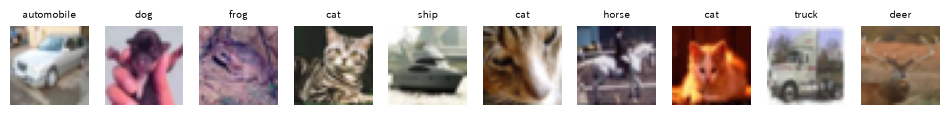

In [18]:
# 補助コード：CIFAR-10 を Hugging Face Hub（datasets ライブラリ）から取得し，一部を取り出す．X は (n, 3, 32, 32)（0〜1）
if HAS_HF:
    from datasets import load_dataset
    cifar = load_dataset("uoft-cs/cifar10")                                   # 初回はダウンロード（約 170 MB）
    CIFAR_CLASSES = cifar["train"].features["label"].names
    tr = cifar["train"].shuffle(seed=0).select(range(3000)); te = cifar["test"].shuffle(seed=0).select(range(2000))
    X_tr = torch.tensor(np.stack([np.array(im) for im in tr["img"]])).float().div(255).permute(0, 3, 1, 2); y_tr = torch.tensor(tr["label"])
    X_te = torch.tensor(np.stack([np.array(im) for im in te["img"]])).float().div(255).permute(0, 3, 1, 2); y_te = torch.tensor(te["label"])
    print("訓練", tuple(X_tr.shape), "テスト", tuple(X_te.shape), "クラス:", CIFAR_CLASSES)
    fig, axes = plt.subplots(1, 10, figsize=(12, 1.6))
    for k, ax in enumerate(axes):
        ax.imshow(X_tr[k].permute(1, 2, 0)); ax.set_title(CIFAR_CLASSES[int(y_tr[k])], fontsize=7); ax.axis("off")
    plt.show()

In [19]:
# 補助コード：ResNet-18 で 512 次元の特徴を計算する（32×32 を 64×64 に拡大し，ImageNet の平均と標準偏差で正規化）
if HAS_HF:
    from torchvision.models import resnet18, ResNet18_Weights

    def resnet_features(X, pretrained=True):
        torch.manual_seed(0)                                    # 乱数初期化のときも，訓練とテストで同じ乱数の重みを使う
        model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1 if pretrained else None, progress=False).eval()
        model.fc = torch.nn.Identity()                          # 分類ヘッドを外し，512 次元の特徴を出す（バックボーンだけにする）
        img = torch.nn.functional.interpolate(X, size=64, mode="bilinear", align_corners=False)
        mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1); std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
        img = (img - mean) / std
        with torch.no_grad():
            return torch.cat([model(img[i:i + 256]) for i in range(0, len(img), 256)])

    def linear_probe(Z_tr, y_tr, Z_te, y_te, n_label, steps=300, seed=0):
        """特徴 Z の上で線形分類器（ソフトマックス回帰）だけを学習し，テスト正解率を返す．ラベルは各クラス n_label 件"""
        g = torch.Generator().manual_seed(seed)
        idx = torch.cat([torch.where(y_tr == c)[0][torch.randperm(int((y_tr == c).sum()), generator=g)[:n_label]] for c in range(10)])
        mu, sd = Z_tr.mean(0, keepdim=True), Z_tr.std(0, keepdim=True) + 1e-6
        Ztr, Zte = (Z_tr[idx] - mu) / sd, (Z_te - mu) / sd      # 特徴を標準化（第6回）
        head = torch.nn.Linear(Ztr.shape[1], 10)
        opt = torch.optim.Adam(head.parameters(), lr=0.01, weight_decay=1e-3)
        for _ in range(steps):
            opt.zero_grad(); torch.nn.functional.cross_entropy(head(Ztr), y_tr[idx]).backward(); opt.step()
        with torch.no_grad():
            return float((head(Zte).argmax(1) == y_te).float().mean())

In [20]:
if HAS_HF:
    feats = {"(a) 画素そのまま（3,072 次元）": (X_tr.reshape(len(X_tr), -1), X_te.reshape(len(X_te), -1)),
             "(b) 乱数初期化の ResNet-18（512 次元）": (resnet_features(X_tr, pretrained=False), resnet_features(X_te, pretrained=False)),
             "(c) 学習済み ResNet-18（512 次元）": (resnet_features(X_tr, pretrained=True), resnet_features(X_te, pretrained=True))}
    print("| 特徴 | ラベル 10 件/クラス | 100 件/クラス | 300 件/クラス |")
    for name, (Ztr, Zte) in feats.items():
        accs = [linear_probe(Ztr, y_tr, Zte, y_te, n) for n in (10, 100, 300)]
        print(f"| {name} | " + " | ".join(f"{a:.2f}" for a in accs) + " |")

| 特徴 | ラベル 10 件/クラス | 100 件/クラス | 300 件/クラス |


| (a) 画素そのまま（3,072 次元） | 0.23 | 0.26 | 0.29 |


| (b) 乱数初期化の ResNet-18（512 次元） | 0.25 | 0.29 | 0.31 |


| (c) 学習済み ResNet-18（512 次元） | 0.55 | 0.64 | 0.68 |


読み方：§5 と同じ構図が実データでも現れる．画素そのまま (a) や乱数初期化の特徴 (b) の上の線形分類器は，ラベルを増やしてもなかなか当たらない．学習済みの特徴 (c) は，ラベルが各クラス 10 件しかなくてもそれらを大きく上回る．ImageNet で学習した表現が，別のデータ（CIFAR-10）でもそのまま「良い特徴」になっている（転移学習，第5回）．

**やってみよう 8-1**　`n_label` を 3 と 1000 にすると，3 つの特徴の差はどうなるか．ラベルが十分にあるとき，線形プローブで足りない部分を Fine-tuning で補う（§6）という判断になる．

In [21]:
if HAS_HF:
    n_label = 30   # TODO: 3 や 300 に変える
    for name, (Ztr, Zte) in feats.items():
        print(f"{name}: 正解率 {linear_probe(Ztr, y_tr, Zte, y_te, n_label):.2f}")

(a) 画素そのまま（3,072 次元）: 正解率 0.26


(b) 乱数初期化の ResNet-18（512 次元）: 正解率 0.26


(c) 学習済み ResNet-18（512 次元）: 正解率 0.60
